# Gamma Alignment Notebook

## Purpose
This notebook aligns the tilt series of many in plane (Γ) rotations. It takes the outputs of `Alpha_Alignment.ipynb`.

1. **Centroid-based alignment** — Track the fiducial hole cluster centroid
   across the tilt series. Fit a sinusoid to y (y shifts with projection)
   and a line to x (slow stage drift). Shift each scan to the fit curve.


## Workflow
1. **Imports**
2. **User Configuration** — all tunable parameters in one place
3. **Load Data** — read CC, XMCD, OD stacks and angle arrays
4. **Single-Scan Preview** — verify fiducial detection on one scan
5. **Centroid Tracking** — compute fiducial centroid for every scan
6. **Fit Centroid Curves** — fit sinusoid (y) and line (x) to centroids
7. **Centroid-Based Alignment** — shift each scan to the fit target
8. **Verify Centroid Alignment** — re-track centroids and plot residuals
11. **Save Outputs**

## Dependencies
All shared functions live in `Functions.py` (same directory) and are accessed
as `register.function_name()`.

---
## Step 1 — Imports

In [1]:
import numpy as np
import os
os.environ["OPENBLAS_NUM_THREADS"] = "1"
import tifffile
import matplotlib as mpl
import matplotlib.pyplot as plt

from scipy.fft import fftn, ifftn
from scipy.ndimage import fourier_shift
from scipy.optimize import curve_fit
import scipy.ndimage as ndimage


import cv2


# All shared functions imported from Functions.py as 'register'
import Functions as register


---
## Step 2 — User Configuration & Load Data

**Edit this cell for every new dataset / Gamma.**
All parameters that vary between samples, Gammas, or processing runs are
defined here and propagated automatically.


In [2]:
def build_file_path(date, modifier, Gamma): 
    data_dir =  f"/homes/emma/notebooks/RawData/{sample}/{Gamma}/"
    fn_CC     = f"center_alpha_aligned_CC{date}_{Gamma}_{modifier}.tiff"
    fn_ASYM   = f"center_alpha_aligned_ASYM{date}_{Gamma}_{modifier}.tiff"
    fn_XMCD   = f"center_alpha_aligned_XMCD{date}_{Gamma}_{modifier}.tiff"
    fn_angles = f"angles_shifted{date}_{Gamma}_{modifier}.txt"

    y_centroid = f"center_y_centroid_aligned{date}_{Gamma}_{modifier}.txt"
    x_centroid = f"center_x_centroid_aligned{date}_{Gamma}_{modifier}.txt"
    
    # --- Load stacks -------------------------------------------------------------
    image_CC   = tifffile.imread(os.path.join(data_dir, fn_CC))
    image_XMCD = tifffile.imread(os.path.join(data_dir, fn_XMCD))
    image_ASYM = tifffile.imread(os.path.join(data_dir, fn_ASYM))

    angles = np.loadtxt(os.path.join(data_dir, fn_angles))

    y = np.loadtxt(os.path.join(data_dir, y_centroid))
    x = np.loadtxt(os.path.join(data_dir, x_centroid))
    
    print(f"Loaded: {data_dir}")
    print(f"  image_CC shape   : {image_CC.shape}")
    print(f"  image_XMCD shape : {image_XMCD.shape}")
    print(f"  image_ASYM shape : {image_ASYM.shape}")
    print(f"  angles shape     : {angles.shape}")
    print(f"  x centroid shape     : {x.shape}")
    print(f"  y centroid shape     : {y.shape}")
    print(f"  angle range      : [{angles[0]:.2f}, {angles[-1]:.2f}] deg")

    return image_CC, image_XMCD, image_ASYM, angles, x, y


# --- Sample Identity ---------------------------------------------------------
sample   = "270"     

if sample == '452':
    modifier = 'bsub_kmeans_rot_log10' #'bsub_kmeans' #'bsub_kmenas'#'normalize_by_kmeans' #
    fiduc_num = 3
    ## 90
    date90  = '_16MAR26_og_ptycho'      
    color_1_90 = 'darkmagenta'    
    color_2_90 = 'm'             
    color_list90 = ['m', 'darkmagenta', 'mediumvioletred', 'palevioletred']
    CC_90, XMCD_90, ASYM_90, angles_90, x_90, y_90 = build_file_path(date90, modifier, Gamma = 'Gamma90')
    ## 0
    date0  = '_1APR26_recon_ptycho'         
    color_1_0 = 'cornflowerblue'    
    color_2_0 = 'royalblue'              
    color_list0 = ['cornflowerblue', 'royalblue', 'tab:blue', 'blue']
    CC_0, XMCD_0, ASYM_0, angles_0, x_0, y_0 = build_file_path(date0, modifier, Gamma = 'Gamma0')
    ## 45
    date45  = '_21MAR26_og_ptycho'
    color_1_45 = 'limegreen'   
    color_2_45 = 'darkgreen'             
    color_list45 = ['limegreen', 'darkgreen', 'tab:green', 'green']
    CC_45, XMCD_45, ASYM_45, angles_45, x_45, y_45 = build_file_path(date45, modifier, Gamma = 'Gamma45')

    # combine all
    x_aligned  = [x_0, x_45, x_90]
    y_aligned  = [y_0, y_45, y_90]
    angles     = [angles_0, angles_45, angles_90]
    Gammas     = ['Gamma0', 'Gamma45', 'Gamma90']
    color_list = [color_list0, color_list45, color_list90]
    CC = [CC_0, CC_45, CC_90]
    XMCD = [XMCD_0, XMCD_45, XMCD_90]
    ASYM = [ASYM_0, ASYM_45, ASYM_90]


    hist_colors = {
        "Gamma0": "cornflowerblue",
        "Gamma45": "limegreen",
        "Gamma90": "darkmagenta",
    }
    mean_line_colors = {
        "Gamma0": "royalblue",
        "Gamma45": "darkgreen",
        "Gamma90": "m",
    }



elif sample == '270':
    modifier = 'bsub_kmeans_rot_log10'#'normalize_by_kmeans' #
    fiduc_num = 3
    ## 90
    date90  = '_29APR26_og_ptycho'      
    color_1_90 = 'darkmagenta'    
    color_2_90 = 'm'             
    color_list90 = ['m', 'darkmagenta', 'mediumvioletred', 'palevioletred']
    CC_90, XMCD_90,ASYM_90, angles_90, x_90, y_90 = build_file_path(date90, modifier, Gamma = 'Gamma90')
    ## 0
    date0  = '_29APR26_og_ptycho_light_on'         
    color_1_0 = 'cornflowerblue'    
    color_2_0 = 'royalblue'              
    color_list0 = ['cornflowerblue', 'royalblue', 'tab:blue', 'blue']
    CC_0, XMCD_0,ASYM_0, angles_0, x_0, y_0 = build_file_path(date0, modifier, Gamma = 'Gamma0')
    ## 45
    date45  = '_29APR26_og_ptycho'
    color_1_45 = 'limegreen'   
    color_2_45 = 'darkgreen'             
    color_list45 = ['limegreen', 'darkgreen', 'tab:green', 'green']
    CC_45, XMCD_45, ASYM_45, angles_45, x_45, y_45 = build_file_path(date45, modifier, Gamma = 'Gamma45')

    # combine all
    x_aligned  = [x_0, x_45, x_90]
    y_aligned  = [y_0, y_45, y_90]
    angles     = [angles_0, angles_45, angles_90]
    Gammas     = ['Gamma0', 'Gamma45', 'Gamma90']
    color_list = [color_list0, color_list45, color_list90]
    CC = [CC_0, CC_45, CC_90]
    XMCD = [XMCD_0, XMCD_45, XMCD_90]
    ASYM = [ASYM_0, ASYM_45, ASYM_90]

    hist_colors = {
        "Gamma0": "cornflowerblue",
        "Gamma45": "limegreen",
        "Gamma90": "darkmagenta",
    }
    mean_line_colors = {
        "Gamma0": "royalblue",
        "Gamma45": "darkgreen",
        "Gamma90": "m",
    }


elif sample == '665':
    fiduc_num = 4
    ## 0 
    date0  = '_3AUG25_check_saturation_n50'         
    color_1_0 = 'cornflowerblue'    
    color_2_0 = 'royalblue'              
    color_list0 = ['cornflowerblue', 'royalblue', 'tab:blue', 'blue']
    CC_0, XMCD_0, angles_0, x_0, y_0 = build_file_path(date0, modifier, Gamma = 'Gamma0')
    
    ## 45
    date45  = '_5AUG25_check_saturation_n50'
    color_1_45 = 'limegreen'    
    color_2_45 = 'darkgreen'              
    color_list45 = ['limegreen', 'darkgreen', 'tab:green', 'green']
    CC_45, XMCD_45, angles_45, x_45, y_45 = build_file_path(date45, modifier, Gamma = 'Gammaneg45')

    # combine all
    x_aligned  = [x_0, x_45]
    y_aligned  = [y_0, y_45]
    angles     = [angles_0, angles_45]
    Gammas     = ['Gamma0', 'Gammaneg45']
    color_list = [color_list0, color_list45]
    CC = [CC_0, CC_45]
    XMCD = [XMCD_0, XMCD_45]


    hist_colors = {
        "Gamma0": "cornflowerblue",
        "Gamma45": "limegreen",
    }
    mean_line_colors = {
        "Gamma0": "royalblue",
        "Gamma45": "darkgreen",
    }

elif sample == '105':
    modifier ='bsub_kmeans_log10'# 'normalize_by_kmeans'
    fiduc_num = 3
    ## 0 
    date0 = '_17NOV25_auto_select_scans_fullrange'
    color_1_0 = 'cornflowerblue'          
    color_2_0 = 'royalblue' 
    color_list0 = ['cornflowerblue', 'royalblue', 'tab:blue', 'blue']
    CC_0, XMCD_0, ASYM_0, angles_0, x_0, y_0 = build_file_path(date0, modifier, Gamma = 'Gamma0')

    ## 45
    date45 = '_19NOV25_select_fullrange'
    color_1_45 = 'limegreen'          
    color_2_45 = 'darkgreen' 
    color_list45 = ['limegreen', 'darkgreen', 'tab:green', 'green']
    CC_45, XMCD_45, ASYM_45, angles_45, x_45, y_45 = build_file_path(date45, modifier, Gamma = 'Gamma45')

    # combine all
    x_aligned  = [x_0, x_45]
    y_aligned  = [y_0, y_45]
    angles     = [angles_0, angles_45]
    Gammas     = ['Gamma0', 'Gamma45']
    color_list = [color_list0, color_list45]
    CC = [CC_0, CC_45]
    XMCD = [XMCD_0, XMCD_45]
    ASYM = [ASYM_0, ASYM_45]

    hist_colors = {
        "Gamma0": "cornflowerblue",
        "Gamma45": "limegreen",
    }
    mean_line_colors = {
        "Gamma0": "royalblue",
        "Gamma45": "darkgreen",
    }



# --- Alignment Parameters ----------------------------------------------------
# factor: pixels above (factor * image_max) treated as fiducial holes.
factor = 1.7 #0.7

# bound: half-width of cross-correlation search window (pixels).
# Can also be specified per-scan in Step 9 via kbad list.
bound = 100

# Centroid y-axis display limits for fit plots (adjust to your image size).
centroid_ylim = (220, 320)

# --- Output Modifier ---------------------------------------------------------
# modifier = 'normalize_by_kmeans'  #'normalize_by_diffraction' #'all_scans_failed_psd'    # e.g. '_v2', '_centroid', '_xcorr'

# --- Summary -----------------------------------------------------------------
print(f"Configuration: Sample {sample}")
print(f"  Fiducials  : {fiduc_num}")
print(f"  factor={factor}, bound={bound}")





Loaded: /homes/emma/notebooks/RawData/270/Gamma90/
  image_CC shape   : (21, 500, 500)
  image_XMCD shape : (21, 500, 500)
  image_ASYM shape : (21, 500, 500)
  angles shape     : (21,)
  x centroid shape     : (21,)
  y centroid shape     : (21,)
  angle range      : [-71.18, 62.28] deg
Loaded: /homes/emma/notebooks/RawData/270/Gamma0/
  image_CC shape   : (50, 500, 500)
  image_XMCD shape : (50, 500, 500)
  image_ASYM shape : (50, 500, 500)
  angles shape     : (50,)
  x centroid shape     : (50,)
  y centroid shape     : (50,)
  angle range      : [-70.29, 59.17] deg
Loaded: /homes/emma/notebooks/RawData/270/Gamma45/
  image_CC shape   : (13, 500, 500)
  image_XMCD shape : (13, 500, 500)
  image_ASYM shape : (13, 500, 500)
  angles shape     : (13,)
  x centroid shape     : (13,)
  y centroid shape     : (13,)
  angle range      : [-69.72, 62.30] deg
Configuration: Sample 270
  Fiducials  : 3
  factor=1.7, bound=100


---
# Step 3
- decide which sin function looks favorable and shift all values to this sin function

In [3]:
## Functions

def fit_sin_and_plot_aligned_centroid(x_aligned, y_aligned, angles, Gammas, color_list):

    y_params_list = [ ]
    x_params_list = [ ]

    fig, ax = plt.subplots(figsize=(15, 4))
    ax.set_xlabel('Tilt angle (deg)')
    ax.set_ylabel('Centroid position (pixels)')
    ax.set_title(f"Compare Centroid Alignment Sample {sample}")
    
    for scan in np.arange(0, len(Gammas)): 
        print(f'scan {scan} is {Gammas[scan]}')
        
        plot_angles     = angles[scan]
        plot_angles_rad = np.deg2rad(plot_angles)

        y_centroid = y_aligned[scan]
        x_centroid = x_aligned[scan]

        #print(f'y shape = {y_centroid.shape}, x shape = {x_centroid.shape}, angles shape = {plot_angles.shape}')

        colors = color_list[scan]
    
        # --- Fit sinusoid to y-centroid -----------------------------------------------
        bounds_sin = ([0, 0, -2 * np.pi], [np.inf, np.inf, 2 * np.pi])
        guess_sin  = [10, np.mean(y_centroid), 6]
        
        y_params, _ = curve_fit(register.sin_fit, plot_angles_rad, y_centroid,
                                p0=guess_sin, bounds=bounds_sin)
        y_params_list.append(y_params)
        y_sin_fit = register.sin_fit(plot_angles_rad, *y_params)
        b_fix = np.pi / np.ptp(plot_angles_rad)
        y_fit_label = (f"y sin fit: {y_params[0]:.2f}*sin({b_fix:.2f}*angle "
                       f"+ {y_params[2]:.2f}) + {y_params[1]:.2f}")
        print(f"{Gammas[scan]}: y sin fit params : {y_params}")
        
        # --- Fit line to x-centroid --------------------------------------------------
        x_params, _ = curve_fit(register.lin_fit, plot_angles_rad, x_centroid, p0=[2, 2])
        x_params_list.append(np.mean(x_centroid))
        x_lin_fit = register.lin_fit(plot_angles_rad, *x_params)
        x_fit_label = f"x lin fit: {x_params[0]:.2f}*angle + {x_params[1]:.2f}"
        print(f"x lin fit params : {x_params}")

        ## plot
        ax.plot(plot_angles, y_centroid, color=colors[0], marker='o',
                linewidth=0.5, label=f'{Gammas[scan]} aligned y centroid, COR = {y_params[1]:.2f}')
        
        ax.plot(plot_angles, y_sin_fit, color=colors[1], linewidth=2, label='y sin fit')
        
        ax.plot(plot_angles, x_centroid, color=colors[2], marker='o',
                linewidth=0.5, label=f'{Gammas[scan]} aligned x centroid, COR = {np.mean(x_centroid):.2f}')
        
        ax.axhline(np.mean(x_centroid), color=colors[3], linewidth=2, label=f'x mean')
    
    ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.tight_layout()
    plt.show()

    return y_params_list, x_params_list

scan 0 is Gamma0
Gamma0: y sin fit params : [  7.48104884 262.73991171   4.69127212]
x lin fit params : [1.32893959e-02 2.40098219e+02]
scan 1 is Gamma45
Gamma45: y sin fit params : [ 51.33218105 260.75690108   4.69497649]
x lin fit params : [1.03280987e-02 2.51428724e+02]
scan 2 is Gamma90
Gamma90: y sin fit params : [ 11.26507822 234.85008833   5.13274233]
x lin fit params : [-8.80233313e-03  2.79948360e+02]


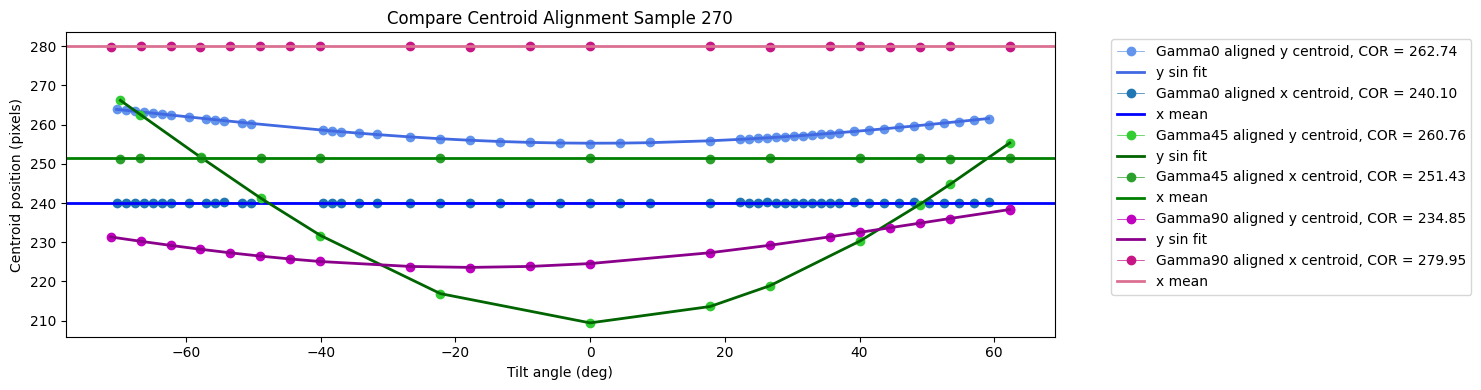

In [4]:
y_params_list, x_params_list = fit_sin_and_plot_aligned_centroid(x_aligned, y_aligned, angles, Gammas, color_list)


In [5]:
sanity_check = False
if sanity_check == True:
    finite_CC = CC[0][30].astype(float)
    finite_mask = np.isfinite(finite_CC)  # True for real numbers, False for nan/inf
    # max over finite pixels only
    mx = finite_CC[finite_mask].max() if np.any(finite_mask) else 0.0
    CC_to_fit = np.full_like(finite_CC, np.nan)   # or 0.0 if you prefer
    CC_to_fit[finite_mask] = mx - finite_CC[finite_mask] 
    
    fig, ax = plt.subplots(1, 2, figsize=(10, 4))
    ax[0].imshow(CC[0][30], cmap='gray')  # middle angle of Gamma0
    ax[0].set_title('CC[0][30] raw')
    ax[1].imshow(CC_to_fit, cmap='gray')
    ax[1].set_title('CC_to_fit (inverted)')
    plt.show()
    
    factor = 1.7
    for k in [0, 15, 30]:
    
        finite_CC = CC[0][k].astype(float)
        finite_mask = np.isfinite(finite_CC)  # True for real numbers, False for nan/inf
        # max over finite pixels only
        mx = finite_CC[finite_mask].max() if np.any(finite_mask) else 0.0
        CC_to_fit = np.full_like(finite_CC, np.nan)   # or 0.0 if you prefer
        CC_to_fit[finite_mask] = mx - finite_CC[finite_mask] 
    
        # CC_to_fit = (CC[0][k]) * -1 + np.nanmax(CC[0][k])
        points = register.find_fiducial_points(CC_to_fit, fiduc_num, factor, verbose=True)
        print(f'k={k}: points found = {len(points)}, points = {points}')

scan 0 is Gamma0
selected scan 0 = scan 0 = Gamma0
scan 0: n_angles=50, centroids collected=50
scan 1 is Gamma45
  k=0: applying shift y=-2.62, x=-11.33
  CC_scan[k] shape=(500, 500), NaN%=0.24
  shift_CC NaN%=0.25
  CC_scan[k] value range: -0.25 to 1.17
  shift_CC value range: -0.2493012547492981
scan 1: n_angles=13, centroids collected=13
scan 2 is Gamma90
  k=0: applying shift y=32.33, x=-39.85
  CC_scan[k] shape=(500, 500), NaN%=0.07
  shift_CC NaN%=0.16
  CC_scan[k] value range: -0.23 to 1.43
  shift_CC value range: -0.22152958810329437
scan 2: n_angles=21, centroids collected=21


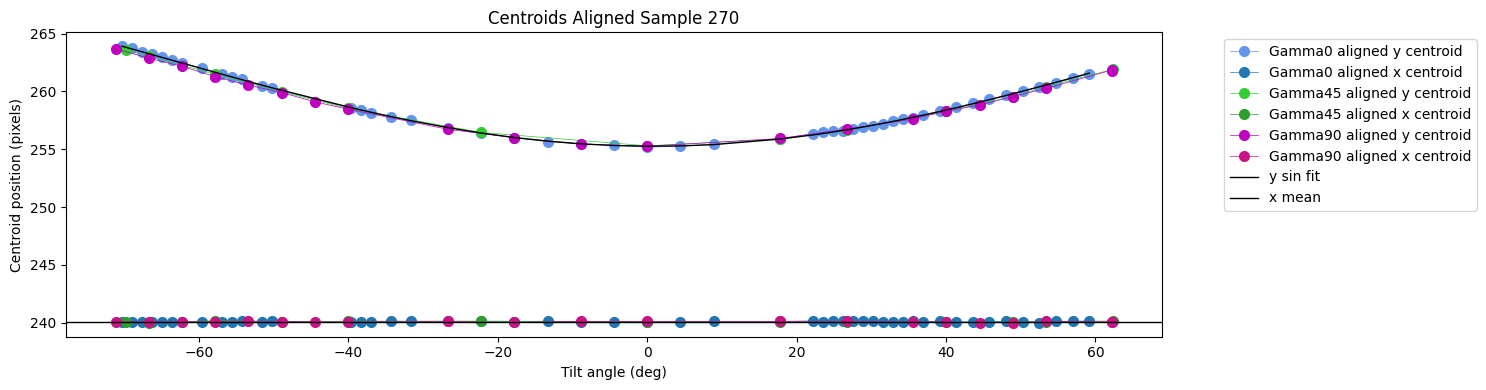

In [6]:
def shift_and_plot(CC, XMCD, x_aligned, y_aligned, angles, x_params_list, y_params_list,
x_param_selected, y_param_selected, selected_scan, Gammas, color_list):

    # One list entry per Gamma; each will become [n_angles, H, W]
    aligned_XMCD = []   # list of 3 stacks
    aligned_CC   = []   # list of 3 stacks
    aligned_ASYM = []   # list of 3 stacks
    final_y_centroid = []  # list of 3 centroid arrays, each length n_angles
    final_x_centroid = []  # list of 3 centroid arrays, each length n_angles

    fig, ax = plt.subplots(figsize=(15, 4))
    ax.set_xlabel('Tilt angle (deg)')
    ax.set_ylabel('Centroid position (pixels)')
    ax.set_title(f"Centroids Aligned Sample {sample}")
        
    # Compute sin fit for selected scan once, outside loop (needed for plot + shifts)
    plot_angles_selected     = angles[selected_scan]
    plot_angles_selected_rad = np.deg2rad(plot_angles_selected)
    y_sin_fit_select = register.sin_fit(plot_angles_selected_rad, *y_param_selected)

    factor = 1.7
    ct = 7

    
    for scan in np.arange(0, len(Gammas)):
        plot_angles     = angles[scan]
        plot_angles_rad = np.deg2rad(plot_angles)
        colors          = color_list[scan]
        n_angles        = CC[scan].shape[0]  # use per-scan shape

        CC_scan = CC[scan]
        XMCD_scan = XMCD[scan]
        ASYM_scan = ASYM[scan]

        print(f'scan {scan} is {Gammas[scan]}')

        scan_CC   = []  # collects n_angles shifted frames for this Gamma
        scan_XMCD = []
        scan_ASYM = []
        scan_y_centroids = []
        scan_x_centroids = []


        # print(f'y_param_selected = {y_param_selected}')
        # print(f'y_params_list[scan] = {y_params_list[scan]}')
        
        # # Also check what the actual centroids looked like before shifting
        # print(f'y_aligned[scan][:3] = {y_aligned[scan][:3]}')
        # print(f'y_aligned[selected_scan][:3] = {y_aligned[selected_scan][:3]}')
        # print(f'CC_scan[0] all NaN before shift? {np.all(np.isnan(CC_scan[0]))}')
        # print(f'CC_scan[0] NaN fraction: {np.mean(np.isnan(CC_scan[0])):.2f}')



        if scan == selected_scan:
            print(f'selected scan {selected_scan} = scan {scan} = {Gammas[scan]}')
            # No spatial shift — iterate angles for consistency and centroid computation
            for k in range(n_angles):
                scan_CC.append(CC_scan[k])
                scan_XMCD.append(XMCD_scan[k])
                scan_ASYM.append(ASYM_scan[k])
                
                finite_CC = CC_scan[k].astype(float)
                finite_mask = np.isfinite(finite_CC)  # True for real numbers, False for nan/inf
                # max over finite pixels only
                mx = finite_CC[finite_mask].max() if np.any(finite_mask) else 0.0
                CC_to_fit = np.full_like(finite_CC, np.nan)   # or 0.0 if you prefer
                CC_to_fit[finite_mask] = mx - finite_CC[finite_mask] 

                # CC_to_fit = (CC_scan[k])*-1 + (np.nanmax(CC_scan[k]))
                points    = register.find_fiducial_points(CC_to_fit, fiduc_num, factor, verbose=False)
                tuple_set = set(tuple(row) for row in points)
                y1, x1    = register.calculate_centroid_points(tuple_set)
                scan_y_centroids.append(y1)
                scan_x_centroids.append(x1)

        else:
            y_sin_fit_select_at_scan = register.sin_fit(plot_angles_rad, *y_param_selected)
            y_sin_fit_to_shift       = register.sin_fit(plot_angles_rad, *y_params_list[scan])
            
            y_shift = y_sin_fit_select_at_scan - y_sin_fit_to_shift
            x_shift = x_param_selected - x_params_list[scan]

            for k in range(n_angles):

                CC_frame = CC_scan[k].copy()
                nan_mask = np.isnan(CC_frame)
                CC_frame[nan_mask] = 0.0
                
                shift_CC = ndimage.shift(CC_frame, shift=(y_shift[k], x_shift), order = 1, mode='constant', cval=0.0)
                
                # Re-apply NaN border based on shifted mask
                nan_mask_shifted = ndimage.shift(nan_mask.astype(float), shift=(y_shift[k], x_shift),
                                                  order = 1, mode='constant', cval=1.0) > 0.5
                shift_CC[nan_mask_shifted] = np.nan
            

                # shift_CC   = ndimage.shift(CC_scan[k],   shift=(y_shift[k], x_shift),
                #                            mode='constant', cval=np.nan)

                if k == 0:
                    print(f'  k=0: applying shift y={y_shift[k]:.2f}, x={x_shift:.2f}')
                    print(f'  CC_scan[k] shape={CC_scan[k].shape}, NaN%={np.mean(np.isnan(CC_scan[k])):.2f}')
                    print(f'  shift_CC NaN%={np.mean(np.isnan(shift_CC)):.2f}')
                    print(f'  CC_scan[k] value range: {np.nanmin(CC_scan[k]):.2f} to {np.nanmax(CC_scan[k]):.2f}')
                    print(f'  shift_CC value range: {np.nanmin(shift_CC) if not np.all(np.isnan(shift_CC)) else "ALL NAN"}')



                XMCD_frame = XMCD_scan[k].copy()
                XMCD_frame[nan_mask] = 0.0  # reuse CC's nan_mask
                shift_XMCD = ndimage.shift(XMCD_frame, shift=(y_shift[k], x_shift), order = 1, mode='constant', cval=0.0)
                shift_XMCD[nan_mask_shifted] = np.nan  

                ASYM_frame = ASYM_scan[k].copy()
                ASYM_frame[nan_mask] = 0.0  # reuse CC's nan_mask
                shift_ASYM = ndimage.shift(ASYM_frame, shift=(y_shift[k], x_shift), order = 1, mode='constant', cval=0.0)
                shift_ASYM[nan_mask_shifted] = np.nan  

                # shift_XMCD = ndimage.shift(XMCD_scan[k], shift=(y_shift[k], x_shift),
                #                            mode='constant', cval=np.nan)
                scan_CC.append(shift_CC)
                scan_XMCD.append(shift_XMCD)
                scan_ASYM.append(shift_ASYM)
                
                # FIX: shift_CC is already [H, W] — no [k] indexing needed
                finite_CC = shift_CC.astype(float)
                finite_mask = np.isfinite(finite_CC)  # True for real numbers, False for nan/inf
                # max over finite pixels only
                mx = finite_CC[finite_mask].max() if np.any(finite_mask) else 0.0
                CC_to_fit = np.full_like(finite_CC, np.nan)   # or 0.0 if you prefer
                CC_to_fit[finite_mask] = mx - finite_CC[finite_mask] 

                
                #CC_to_fit = (shift_CC) * -1 + (np.nanmax(shift_CC))
                points    = register.find_fiducial_points(CC_to_fit, fiduc_num, factor, verbose=False)
                tuple_set = set(tuple(row) for row in points)
                y1, x1    = register.calculate_centroid_points(tuple_set)
                scan_y_centroids.append(y1)
                scan_x_centroids.append(x1)

                # print(f'scan {scan}, k={k}: shift_CC all NaN? {np.all(np.isnan(shift_CC))}, y1={y1}, x1={x1}')
                # print(f'x_param_selected = {x_param_selected}, type = {type(x_param_selected)}')
                # print(f'x_params_list[scan] = {x_params_list[scan]}, type = {type(x_params_list[scan])}')
                # print(f'x_shift = {x_shift}, type = {type(x_shift)}')

                # print(f'y_shift range: min={y_shift.min():.2f}, max={y_shift.max():.2f}')
                # print(f'y_shift[0] = {y_shift[0]:.2f}')
                # print(f'CC_scan[0] shape: {CC_scan[0].shape}')
                # print(f'y_sin_fit_select_at_scan[:3] = {y_sin_fit_select_at_scan[:3]}')
                # print(f'y_sin_fit_to_shift[:3] = {y_sin_fit_to_shift[:3]}')
        

        # Stack frames → [n_angles, H, W] and store per Gamma
        aligned_CC.append(np.stack(scan_CC,     axis=0))
        aligned_XMCD.append(np.stack(scan_XMCD, axis=0))
        aligned_ASYM.append(np.stack(scan_ASYM, axis=0))
        final_y_centroid.append(scan_y_centroids)
        final_x_centroid.append(scan_x_centroids)

        # Plot centroids for this Gamma (length now correctly == n_angles)
        ax.plot(plot_angles, scan_y_centroids, color=colors[0], marker='o',
                linewidth=0.5, markersize = ct, label=f'{Gammas[scan]} aligned y centroid')
        ax.plot(plot_angles, scan_x_centroids, color=colors[2], marker='o', 
                linewidth=0.5, markersize = ct,
                label=f'{Gammas[scan]} aligned x centroid')


        print(f'scan {scan}: n_angles={n_angles}, centroids collected={len(scan_y_centroids)}')

    
    ax.plot(plot_angles_selected, y_sin_fit_select, color='k', linewidth=1, label='y sin fit')
    ax.axhline(x_param_selected, color='k', linewidth=1, label='x mean')
    ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.tight_layout()
    plt.show()

    return aligned_XMCD, aligned_CC, aligned_ASYM, final_x_centroid, final_y_centroid


selected_scan    = 0  ### Gamma = 0
y_param_selected = y_params_list[selected_scan]
x_param_selected = x_params_list[selected_scan]

aligned_XMCD, aligned_CC, aligned_ASYM, final_x_centroid, final_y_centroid = shift_and_plot(CC, XMCD, x_aligned, y_aligned, angles,
    x_params_list, y_params_list, x_param_selected, y_param_selected,
    selected_scan, Gammas, color_list
)

---
# Step 4. Visual check to make sure everything looks good

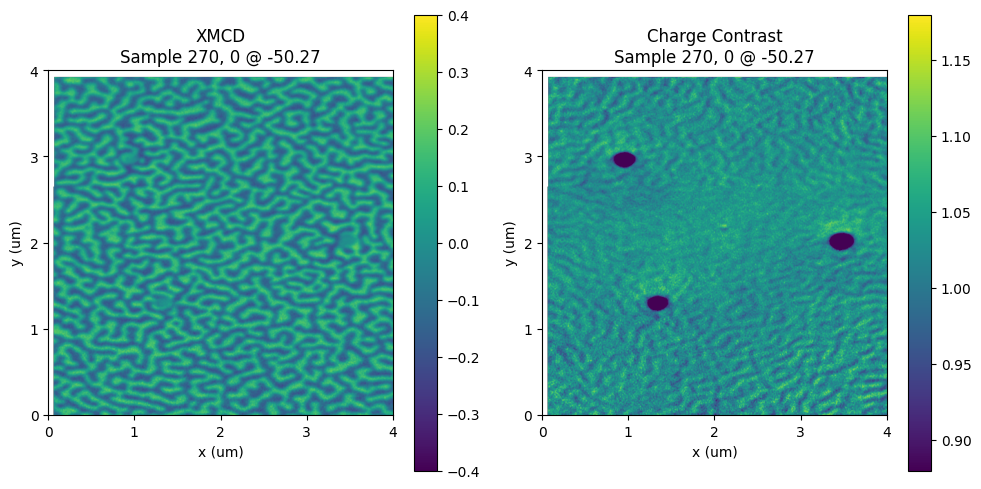

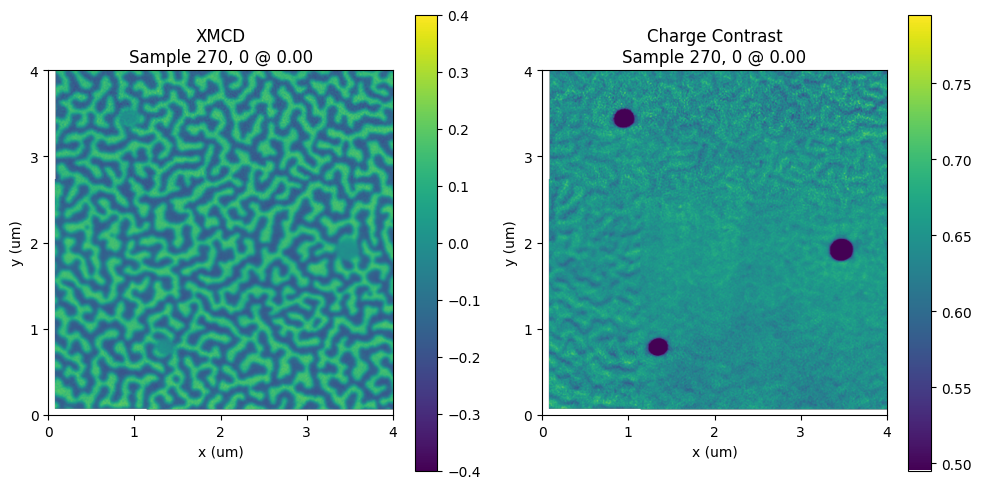

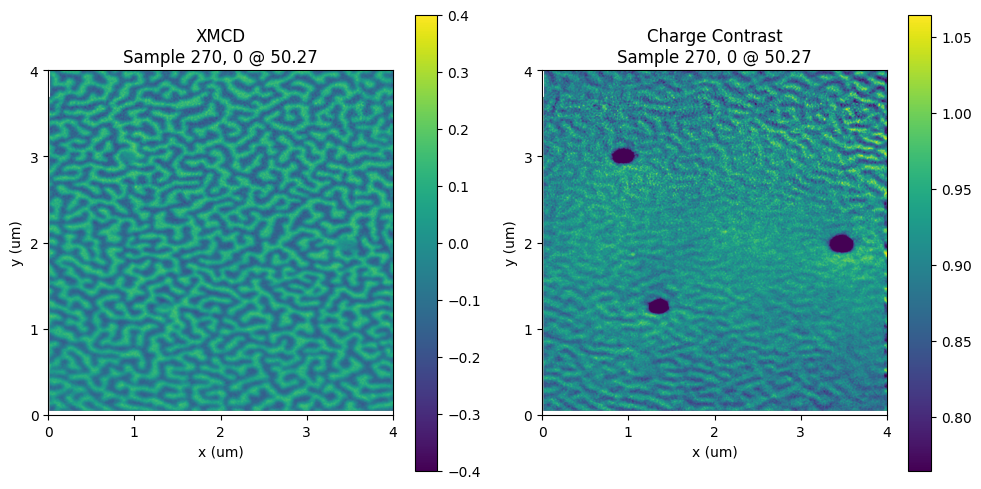

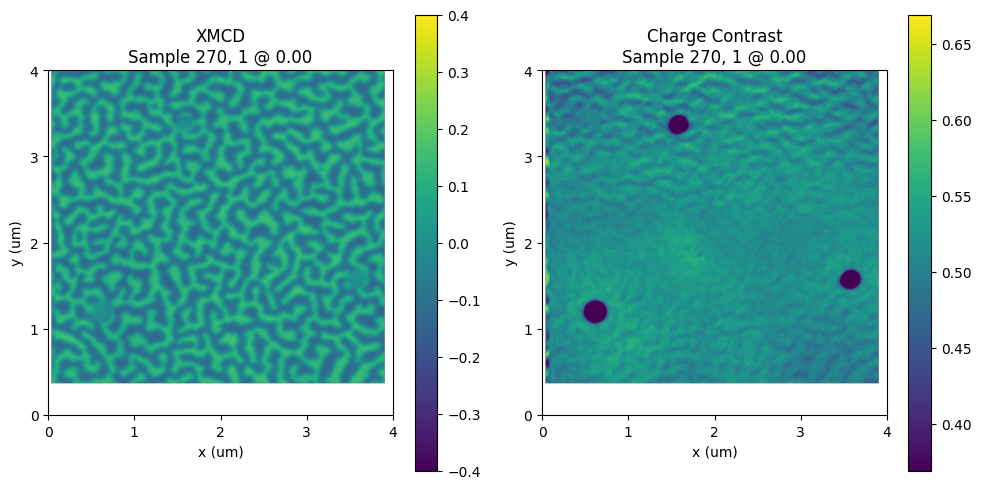

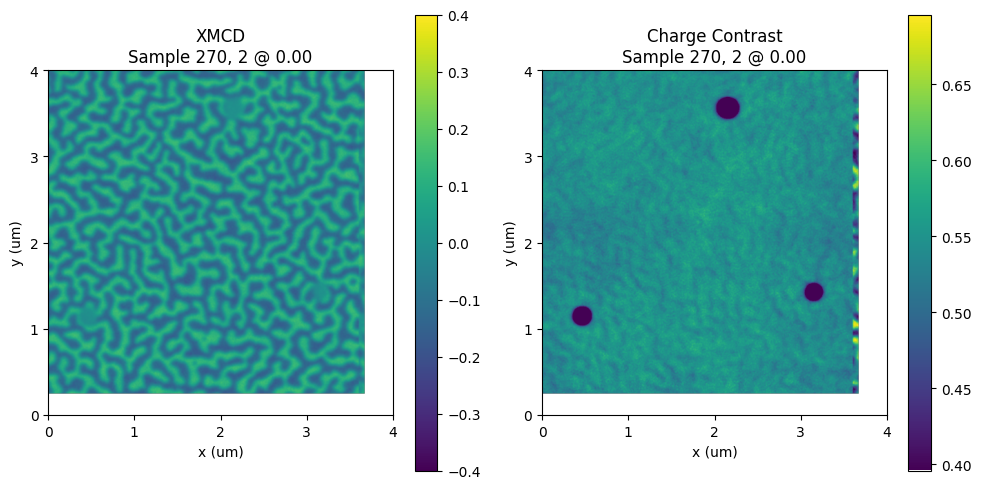

In [7]:
# k_list = [3, 30, 45]

# for Gamma in np.arange(0, len(Gammas)): 
#     for k in k_list: 
#         angle = angles[Gamma][k]
#         register.plot_XMCD_CC_normalizeCC(
#             aligned_XMCD[Gamma][k], aligned_CC[Gamma][k],
#             angle=angle, sample=sample, Gamma=Gamma
#         )

target_angles = [-50, 0, 50]   # <-- put your desired angles here
angle_tolerance = 1.0          # +/- degrees


for Gamma in np.arange(0, len(Gammas)):
    for target_angle in target_angles:

        # Find the k whose angle is closest to target_angle for this Gamma
        gamma_angles = np.array(angles[Gamma])
        diffs = np.abs(gamma_angles - target_angle)
        best_k = int(np.argmin(diffs))
        actual_angle = gamma_angles[best_k]

        # Optionally warn if the closest match is outside tolerance
        if diffs[best_k] > angle_tolerance:
            print(f"Warning: Gamma={Gammas[Gamma]}, target={target_angle}° — "
                  f"closest angle is {actual_angle:.2f}° (Δ={diffs[best_k]:.2f}°), outside tolerance")
            continue  # skip this Gamma for this target angle

        xmcd_data = aligned_XMCD[Gamma][best_k]
        cc_data   = aligned_CC[Gamma][best_k]

        register.plot_XMCD_CC_normalizeCC(
            xmcd_data, cc_data,
            angle=actual_angle, sample=sample, Gamma=Gamma
        )
            
        

# Check constrast at different scans

In [8]:
## quantify decrease in contrast 

"""
contrast_compare.py
--------------------
Quantify contrast reduction between two images.

Metrics reported:
  • Michelson Contrast — (Lmax - Lmin) / (Lmax + Lmin)
  • SNR (dB)           — mean / std of pixel intensities (signal-to-noise)

"""

import sys
import numpy as np
from PIL import Image

try:
    from skimage.metrics import structural_similarity as ssim
    SKIMAGE_AVAILABLE = True
except ImportError:
    SKIMAGE_AVAILABLE = False


# ─────────────────────────────────────────────
# Metric functions
# ─────────────────────────────────────────────

def to_grayscale_array(img: Image.Image) -> np.ndarray:
    """Convert PIL image to float32 grayscale array in [0, 1]."""
    return np.array(img.convert("L"), dtype=np.float32) / 255.0


def michelson_contrast(arr: np.ndarray) -> float:
    """
    Michelson contrast = (Lmax - Lmin) / (Lmax + Lmin).
    Range [0, 1]. Best for periodic / grating patterns.
    """
    lmax = arr.max()
    lmin = arr.min()


    # print(f'lmax = {lmax}, lmin = {lmin}')
    denom = lmax + lmin
    # print(f'denom = {denom}')
    # print(f'num = {(lmax - lmin)}')
    if denom == 0:
        return 0.0
    contrast = ((lmax - lmin) / denom)
    return contrast


def snr_db(arr: np.ndarray) -> float:
    """
    Signal-to-Noise Ratio in dB, treating mean as signal and std as noise.
    SNR(dB) = 20 * log10(mean / std)
    A higher SNR means low contrast (signal dominates, little variation).
    A lower SNR means more texture/contrast relative to the mean level.
    """
    std = np.std(arr)
    mean = np.mean(arr)
    if std == 0 or mean == 0:
        return float("inf") if std == 0 else float("-inf")
    return float(20 * np.log10(mean / std))


def percent_change(original: float, new: float) -> float:
    """% change from original to new value."""
    if original == 0:
        return float("nan")
    return (new - original) / abs(original) * 100.0


import numpy as np
from scipy.signal import find_peaks
from scipy.ndimage import gaussian_filter1d

def xmcd_peak_separation(intensities, bins=200, smooth_sigma=2.0):
    """
    Compute contrast as peak separation for a bimodal XMCD intensity distribution.
    
    Parameters
    ----------
    intensities : array-like
        Flat array of pixel intensity values.
    bins : int
        Number of histogram bins.
    smooth_sigma : float
        Gaussian smoothing applied to histogram before peak finding.

    Returns
    -------
    dict with keys:
        peak_positions   : (float, float) — intensity values of the two peaks
        peak_separation  : float          — |μ₁ − μ₂|
        d_prime          : float          — separation / (σ₁ + σ₂), SNR-normalized
    """
    intensities = np.asarray(intensities).flatten()

    # Build and smooth histogram
    counts, edges = np.histogram(intensities, bins=bins)
    centers = (edges[:-1] + edges[1:]) / 2
    smoothed = gaussian_filter1d(counts.astype(float), sigma=smooth_sigma)

    # Find peaks — require some minimum prominence to avoid noise
    prominence_threshold = smoothed.max() * 0.1
    peaks, props = find_peaks(smoothed, prominence=prominence_threshold)

    if len(peaks) < 2:
        raise ValueError(f"Expected 2 peaks, found {len(peaks)}. "
                         "Try adjusting bins or smooth_sigma.")

    # Take the two most prominent peaks
    prominences = props["prominences"]
    top2_idx = np.argsort(prominences)[-2:]
    top2_peaks = sorted(peaks[top2_idx])  # left peak first

    mu1, mu2 = centers[top2_peaks[0]], centers[top2_peaks[1]]
    peak_separation = abs(mu2 - mu1)

    # Estimate per-peak std by fitting a window around each peak
    def peak_std(peak_idx, window=20):
        lo = max(0, peak_idx - window)
        hi = min(len(centers), peak_idx + window)
        weights = smoothed[lo:hi]
        c = centers[lo:hi]
        mu = np.average(c, weights=weights)
        return np.sqrt(np.average((c - mu) ** 2, weights=weights))

    sigma1 = peak_std(top2_peaks[0])
    sigma2 = peak_std(top2_peaks[1])
    d_prime = peak_separation / (sigma1 + sigma2) if (sigma1 + sigma2) > 0 else np.inf

    # return {
    #     "peak_positions":  (mu1, mu2),
    #     "peak_separation": peak_separation,
    #     "d_prime":         d_prime,
    # }

    return peak_separation

In [9]:
def nearest_angle_index(angle_array, target_angle):
    angle_array = np.asarray(angle_array)
    return int(np.argmin(np.abs(angle_array - target_angle)))

# def build_compare_dict_for_target_angle(
#     target_angle,
#     Gammas,
#     angles,
#     aligned_CC,
#     aligned_XMCD
# ):
#     """
#     Returns compare_dict structured as:
#     {
#       "Gamma0": {"CC": aligned_CC[idx_gamma][k], "XMCD": aligned_XMCD[idx_gamma][k]},
#       "Gamma45": {...},
#       ...
#     }
#     where k is nearest index to target_angle for each Gamma.
#     """
#     compare_dict = {}
#     chosen_indices = {}

#     for i, g in enumerate(Gammas):
#         k = nearest_angle_index(angles[i], target_angle)
#         chosen_indices[g] = k

#         compare_dict[g] = {
#             "CC": aligned_CC[i][k],       # [H, W]
#             "XMCD": aligned_XMCD[i][k],   # [H, W]
#         }

#     return compare_dict, chosen_indices

def build_compare_dict_for_target_angle(
    target_angle,
    Gammas,
    angles,
    aligned_CC,
    aligned_XMCD, 
    aligned_ASYM
):
    """
    Returns compare_dict structured as:
    {
      "CC": {
          "Gamma0": aligned_CC[0][k0],
          "Gamma45": aligned_CC[1][k1],
          "Gamma90": aligned_CC[2][k2],
      },
      "XMCD": {
          "Gamma0": aligned_XMCD[0][k0],
          "Gamma45": aligned_XMCD[1][k1],
          "Gamma90": aligned_XMCD[2][k2],
      }
    }

    where k_i is nearest index to target_angle for each Gamma i.
    """
    compare_dict = {"CC": {}, "XMCD": {}, "ASYM": {}}
    chosen_indices = {}
    chosen_angles = {}

    for i, g in enumerate(Gammas):
        k = nearest_angle_index(angles[i], target_angle)
        chosen_indices[g] = k
        chosen_angles[g] = float(angles[i][k])

        compare_dict["CC"][g] = aligned_CC[i][k]       # [H, W]
        compare_dict["XMCD"][g] = aligned_XMCD[i][k]   # [H, W]
        compare_dict["ASYM"][g] = aligned_ASYM[i][k]   # [H, W]

    return compare_dict, chosen_indices, chosen_angles

def build_color_maps_for_conditions(Gammas, color_list):
    """
    For your plot_hist_compare_dict format (conditions are 'CC' and 'XMCD'):
    hist_colors[condition], mean_line_colors[condition] are global in your current function.
    So to preserve per-Gamma colors, easiest is:
      - keep condition colors fixed OR
      - (recommended) use Gamma colors in title/legend text only.
    
    If you want true per-Gamma-per-condition colors, your plotting function needs a small extension.
    For now we define condition colors globally:
    """
    hist_colors = {"CC": "tab:blue", "XMCD": "tab:orange"}
    mean_line_colors = {"CC": "royalblue", "XMCD": "darkorange"}
    return hist_colors, mean_line_colors

-50 deg = {'Gamma0': 12, 'Gamma45': 3, 'Gamma90': 5}


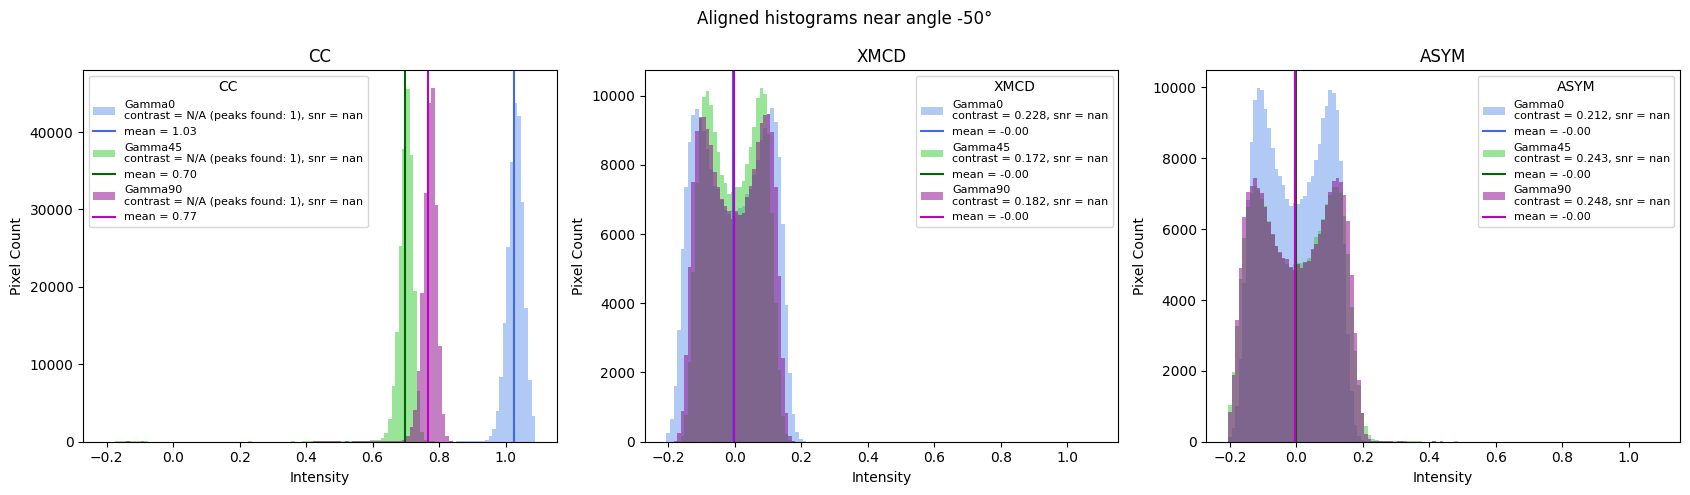

0 deg = {'Gamma0': 24, 'Gamma45': 6, 'Gamma90': 11}


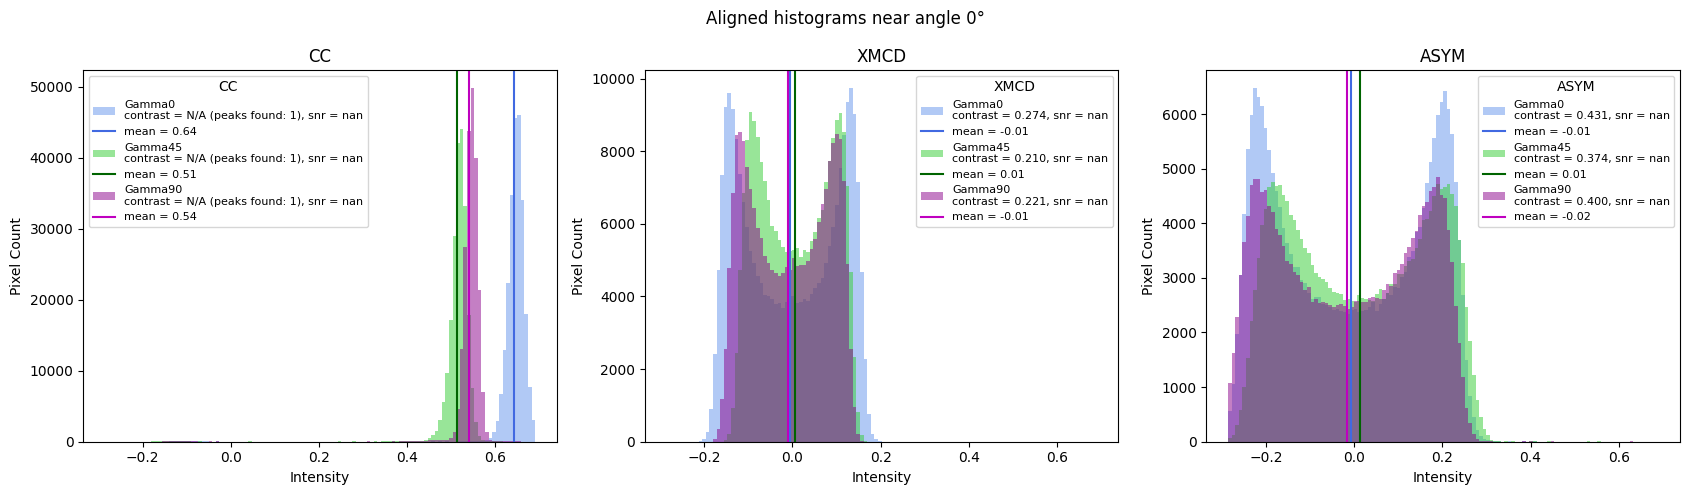

50 deg = {'Gamma0': 45, 'Gamma45': 10, 'Gamma90': 17}


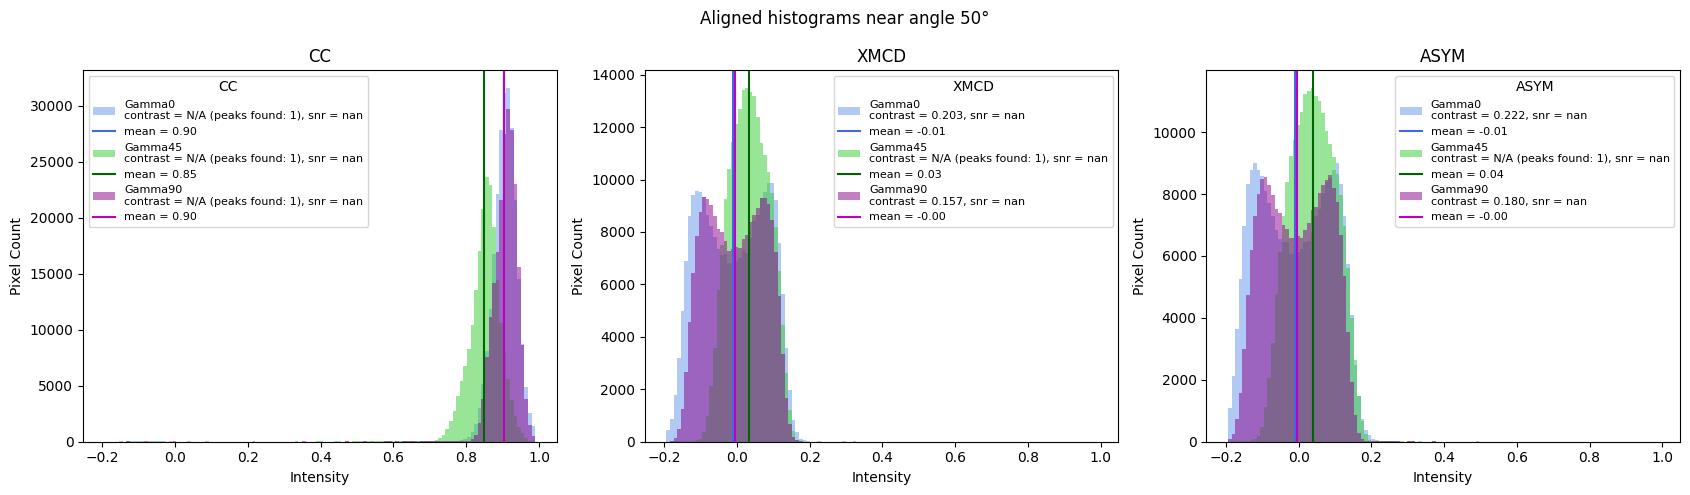

In [10]:
target_angles = [-50,  0, 50]  # choose yours

for target in target_angles:
    compare_dict, chosen_idx, chosen_ang = build_compare_dict_for_target_angle(
        target_angle=target,
        Gammas=Gammas,
        angles=angles,
        aligned_CC=aligned_CC,
        aligned_XMCD=aligned_XMCD, 
        aligned_ASYM=aligned_ASYM
    )

    print(f'{target} deg = {chosen_idx}')
    register.plot_hist_compare_dict(
        compare_dict=compare_dict,
        bins=120,
        robust_range_pct=(0.1, 99.9),
        shared_range=True,
        report_clipped=True,
        use_safe_peak_contrast=True,   # <- your requested behavior
        peak_prominence=None,          # or set e.g. 200
        peak_distance=5,
        figsize=(17, 5),
        show_mean_lines=True, 
        hist_colors=hist_colors,
        mean_line_colors=mean_line_colors,
        suptitle=f"Aligned histograms near angle {target}°"
    )
    

In [11]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import find_peaks

def _safe_peak_contrast(vals, bins=256, hist_range=None, prominence=None, distance=None):
    vals = np.asarray(vals).ravel()
    vals = vals[np.isfinite(vals)]
    if vals.size == 0:
        return None, 0

    counts, edges = np.histogram(vals, bins=bins, range=hist_range)
    centers = 0.5 * (edges[:-1] + edges[1:])

    if prominence is None:
        prominence = 0.05 * np.max(counts) if np.max(counts) > 0 else 1

    peak_idx, _ = find_peaks(counts, prominence=prominence, distance=distance)
    n_peaks = len(peak_idx)

    if n_peaks < 2:
        return None, n_peaks

    peak_pos = np.sort(centers[peak_idx])
    contrast = float(peak_pos[-1] - peak_pos[0])  # furthest two
    return contrast, n_peaks


def plot_hist_compare_dict(
    compare_dict,
    bins=100,
    alpha=0.5,
    figsize=(14, 4),
    show_mean_lines=True,
    mean_line_colors=None,
    hist_colors=None,
    suptitle=None,
    legend_fontsize=8,
    robust_range_pct=None,       # e.g. (1, 99)
    shared_range=True,
    report_clipped=False,
    use_safe_peak_contrast=True,
    peak_prominence=None,
    peak_distance=None,
    contrast_hist_bins=256,
    # NEW:
    plot_contrast_summary=False,
    gamma_order=None,            # e.g. ["Gamma0","Gamma45","Gamma90"]
    reference_gamma=None         # default: first in gamma_order
):
    group_names = list(compare_dict.keys())  # e.g. ["CC","XMCD"]
    n_groups = len(group_names)

    # infer gamma/condition order from first group
    first_group_conditions = list(compare_dict[group_names[0]].keys())
    if gamma_order is None:
        gamma_order = first_group_conditions

    if reference_gamma is None:
        reference_gamma = gamma_order[0]

    # shared robust range
    global_lohi = None
    if robust_range_pct is not None and shared_range:
        all_vals = []
        for g in group_names:
            for _, img in compare_dict[g].items():
                v = np.asarray(img).ravel()
                v = v[np.isfinite(v)]
                if v.size:
                    all_vals.append(v)
        if all_vals:
            cat = np.concatenate(all_vals)
            lo, hi = np.percentile(cat, robust_range_pct)
            global_lohi = (lo, hi)

    # layout
    if plot_contrast_summary:
        fig, axes = plt.subplots(2, n_groups, figsize=(max(figsize[0], 6*n_groups), 8), squeeze=False)
        top_axes = axes[0]
        bot_axes = axes[1]
    else:
        fig, axes = plt.subplots(1, n_groups, figsize=figsize, squeeze=False)
        top_axes = axes[0]
        bot_axes = None

    # store contrast results per group
    contrast_by_group = {g: {} for g in group_names}

    # ---------- top row: histograms ----------
    for i, group in enumerate(group_names):
        ax = top_axes[i]
        condition_dict = compare_dict[group]

        group_lohi = None
        if robust_range_pct is not None and not shared_range:
            gvals = []
            for _, img in condition_dict.items():
                v = np.asarray(img).ravel()
                v = v[np.isfinite(v)]
                if v.size:
                    gvals.append(v)
            if gvals:
                gc = np.concatenate(gvals)
                lo, hi = np.percentile(gc, robust_range_pct)
                group_lohi = (lo, hi)

        hist_range = global_lohi if global_lohi is not None else group_lohi

        for cond_name in gamma_order:
            if cond_name not in condition_dict:
                continue
            img = condition_dict[cond_name]

            vals = np.asarray(img).ravel()
            vals = vals[np.isfinite(vals)]
            if vals.size == 0:
                continue

            mean_val = np.mean(vals)
            snr = register.snr_db(img) if register is not None else np.nan

            if use_safe_peak_contrast:
                contrast, n_peaks = _safe_peak_contrast(
                    vals, bins=contrast_hist_bins, hist_range=hist_range,
                    prominence=peak_prominence, distance=peak_distance
                )
                contrast_txt = f"contrast=N/A (peaks={n_peaks})" if contrast is None else f"contrast={contrast:.3f}"
            elif group == 'CC': ###########################################################################################################################
                contrast = michelson_contrast(img)
            else:
                contrast = register.xmcd_peak_separation(img) if register is not None else np.nan
                contrast_txt = f"contrast={contrast:.3f}"

            contrast_by_group[group][cond_name] = contrast

            clip_txt = ""
            if report_clipped and hist_range is not None:
                lo, hi = hist_range
                n_low = int(np.sum(vals < lo))
                n_high = int(np.sum(vals > hi))
                clip_txt = f"\nclip low/high={n_low}/{n_high}"

            hcolor = hist_colors.get(cond_name) if hist_colors else None
            label = f"{cond_name}\n{contrast_txt}, snr={snr:.3f}{clip_txt}"
            ax.hist(vals, bins=bins, range=hist_range, alpha=alpha, color=hcolor, label=label)

            if show_mean_lines:
                mcolor = mean_line_colors.get(cond_name) if mean_line_colors else None
                ax.axvline(mean_val, color=mcolor, linewidth=1.5, label=f"mean={mean_val:.2f}")

        ax.set_title(group)
        ax.set_xlabel("Intensity")
        ax.set_ylabel("Pixel Count")
        ax.legend(title=f"{group}", fontsize=legend_fontsize)

    # ---------- bottom row: contrast summary ----------
    if plot_contrast_summary:
        for i, group in enumerate(group_names):
            ax = bot_axes[i]

            gammas = [g for g in gamma_order if g in contrast_by_group[group]]
            cvals = [contrast_by_group[group][g] for g in gammas]

            # absolute contrast
            ax.plot(gammas, cvals, '-o', color='red', label=f'{group} contrast')
            ax.set_ylabel("Contrast")
            ax.set_title(f"{group} contrast summary")

            # % diff from reference on twin axis
            ax2 = ax.twinx()
            ref = contrast_by_group[group].get(reference_gamma, None)
            pdiff = []
            for c in cvals:
                if c is None or ref is None or ref == 0:
                    pdiff.append(np.nan)
                else:
                    pdiff.append((c - ref) / ref * 100.0)

            ax2.plot(gammas, pdiff, '-o', color='black', label=f'% diff from {reference_gamma}')
            ax2.set_ylabel(f"% difference from {reference_gamma}")

            # combined legend
            h1, l1 = ax.get_legend_handles_labels()
            h2, l2 = ax2.get_legend_handles_labels()
            ax.legend(h1 + h2, l1 + l2, loc='best', fontsize=legend_fontsize)

    if suptitle is not None:
        fig.suptitle(suptitle)

    plt.tight_layout()
    plt.show()

    return contrast_by_group


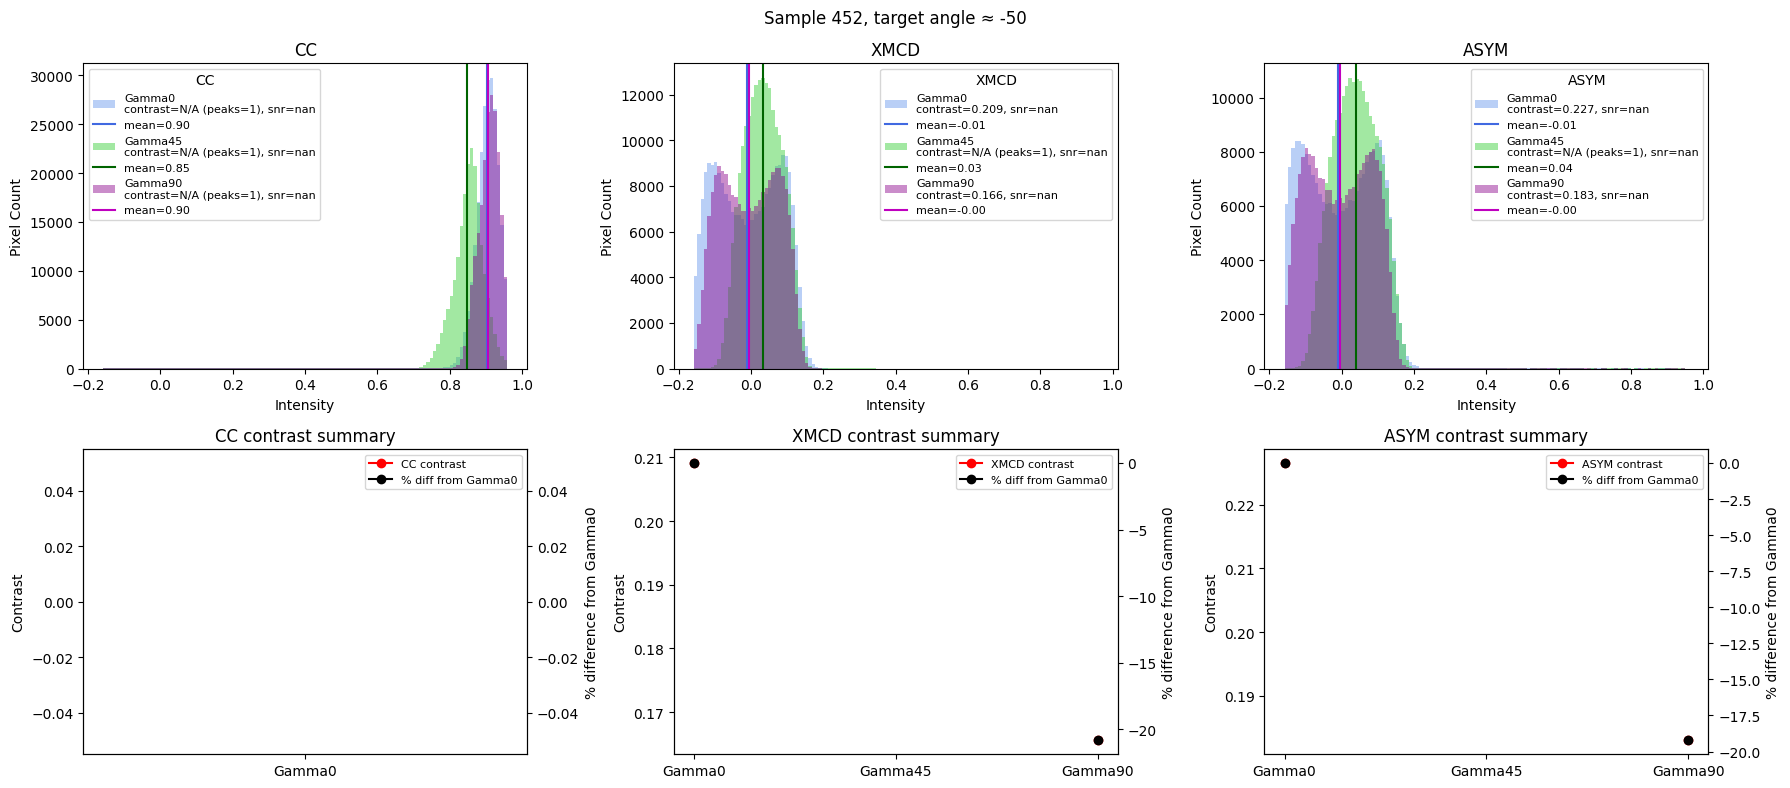

In [12]:
contrast_results = plot_hist_compare_dict(
    compare_dict=compare_dict,  # {"CC": {...}, "XMCD": {...}}
    bins=120,
    alpha=0.45,
    show_mean_lines=True,
    hist_colors={
        "Gamma0": "cornflowerblue",
        "Gamma45": "limegreen",
        "Gamma90": "darkmagenta"
    },
    mean_line_colors={
        "Gamma0": "royalblue",
        "Gamma45": "darkgreen",
        "Gamma90": "m"
    },
    robust_range_pct=(1, 99),
    shared_range=True,
    use_safe_peak_contrast=True,
    plot_contrast_summary=True,          # <-- new
    gamma_order=["Gamma0", "Gamma45", "Gamma90"],
    reference_gamma="Gamma0",
    suptitle="Sample 452, target angle ≈ -50"
)

ValueError: supplied range of [-0.23840293288230896, inf] is not finite

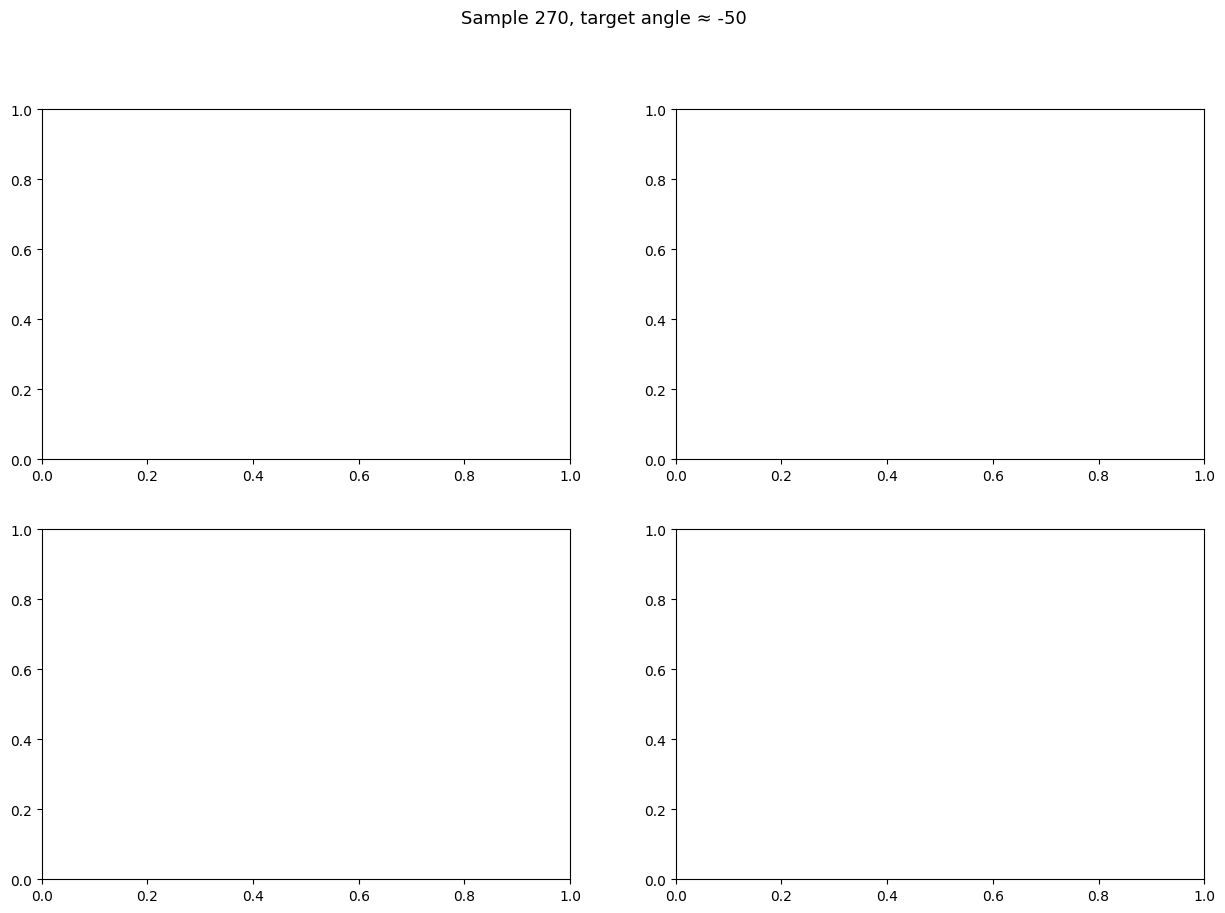

In [13]:
target_angles = [-50, 0, 50]   # <-- put your desired angles here
angle_tolerance = 1.0          # +/- degrees

for target_angle in target_angles:
    fig, axes = plt.subplots(2, 2, figsize=(15, 10))
    fig.suptitle(f"Sample {sample}, target angle ≈ {target_angle}", fontsize=13)

    ax_xmcd = axes[0,0]
    ax_cc   = axes[0,1]
    ax_plot = axes[1,0]
    ax_percent = axes[1,1]
    

    XMCD_contrast = [ ]
    CC_contrast = [ ]
    XMCD_SNR = []
    CC_SNR = []
    delta_XMCD = []
    delta_CC = []

    for Gamma in np.arange(0, len(Gammas)):

        # Find the k whose angle is closest to target_angle for this Gamma
        gamma_angles = np.array(angles[Gamma])
        diffs = np.abs(gamma_angles - target_angle)
        best_k = int(np.argmin(diffs))
        actual_angle = gamma_angles[best_k]

        # Optionally warn if the closest match is outside tolerance
        if diffs[best_k] > angle_tolerance:
            print(f"Warning: Gamma={Gammas[Gamma]}, target={target_angle}° — "
                  f"closest angle is {actual_angle:.2f}° (Δ={diffs[best_k]:.2f}°), outside tolerance")
            continue  # skip this Gamma for this target angle

        label = f'Γ={Gammas[Gamma]}, {actual_angle:.2f}°'

        xmcd_data = aligned_XMCD[Gamma][best_k]
        cc_data   = aligned_CC[Gamma][best_k]

        xmcd_clean = xmcd_data[~np.isnan(xmcd_data)]
        cc_clean   = cc_data[~np.isnan(cc_data)]

        ax_xmcd.hist(xmcd_clean, bins=100, alpha=0.5, label=label)
        ax_cc.hist(cc_clean,   bins=100, alpha=0.5, label=label)

        contrast_XMCD = xmcd_peak_separation(xmcd_clean) 
        contrast_CC = michelson_contrast(cc_clean)

        snr_XMCD = snr_db(xmcd_clean) 
        snr_CC = snr_db(cc_clean)

        XMCD_contrast.append(contrast_XMCD)
        CC_contrast.append(contrast_CC)
        XMCD_SNR.append(snr_XMCD)
        CC_SNR.append(snr_CC)

        if Gamma == 0: 
            XMCD_C_0 = contrast_XMCD
            CC_C_0 = contrast_CC

        delta_XMCD.append(percent_change(XMCD_C_0, contrast_XMCD)) 
        delta_CC.append(percent_change(CC_C_0, contrast_CC)) 



        # print('===================================================================================')
        # print(f"{Gammas[Gamma]} @ {target_angle} deg. \n XMCD Contrast = {contrast_XMCD} and CC Contrast = {contrast_CC} \n XMCD snr = {snr_XMCD} and CC snr = {snr_CC}") 
        # print('===================================================================================')      


    
    ax_xmcd.set_title('aligned_XMCD')
    ax_xmcd.set_xlabel('Intensity')
    ax_xmcd.set_ylabel('Pixel Count')
    ax_xmcd.legend(title='Gamma @ actual angle', fontsize=8)

    ax_cc.set_title('aligned_CC')
    ax_cc.set_xlabel('Intensity')
    ax_cc.set_ylabel('Pixel Count')
    ax_cc.legend(title='Gamma @ actual angle', fontsize=8)


    ax_plot.plot(Gammas, XMCD_contrast, marker = 'o', color = 'k', label = f'XMCD peak separation')  
    ax_plot.plot(Gammas, CC_contrast, marker = 'o', color = 'red', label = f'CC Contrast')  
    ax_plot.set_xlabel('Gamma')
    ax_plot.set_ylabel('Contrast')
    ax_plot.legend(fontsize=8)

    ax_percent.plot(Gammas, delta_XMCD, marker = 'o', color = 'k', label = f'XMCD peak separation')  
    ax_percent.plot(Gammas, delta_CC, marker = 'o', color = 'red', label = f'CC Contrast')  
    ax_percent.set_xlabel('Gamma')
    ax_percent.set_ylabel('% difference from Gamma 0 ')
    ax_percent.legend(fontsize=8)
    

    plt.tight_layout()
    plt.show()


    

In [ ]:
stop

# Check the true Gamma rotation

(500,)

--- Comparing Gamma0 vs Gamma45 ---
alpha(0) = 0.00 deg.
alpha(1) = 0.00 deg.


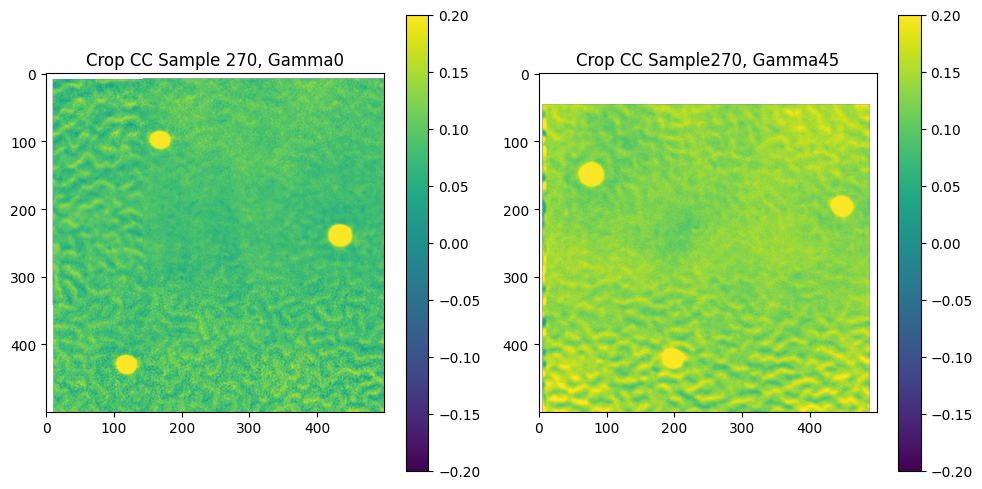

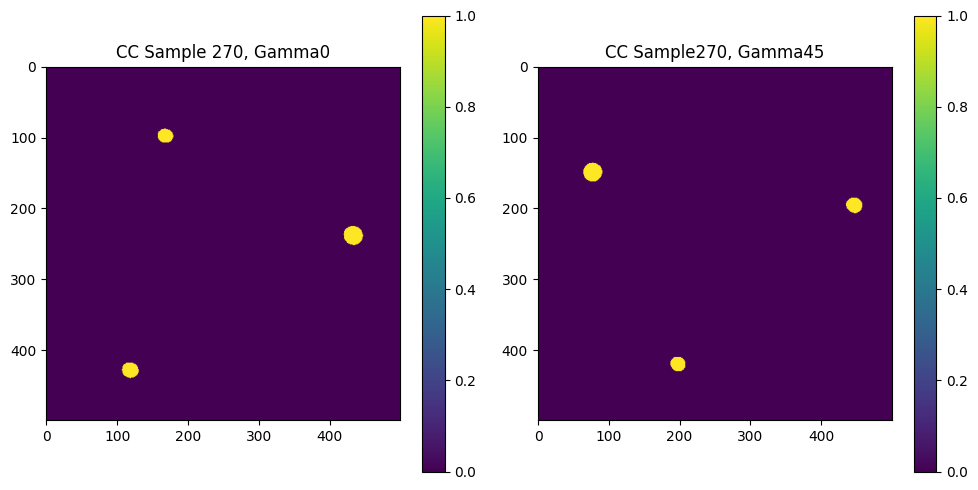

angle_clockwise=-159.28 deg, tx=596.11, ty=223.27, inliers=5
Rotation angle: -159.28 degrees for Gamma[0] -> Gamma[1].


NameError: name 'compute_difference' is not defined

In [14]:
from itertools import combinations

if sample == '452':
    k_0_list = [27, 34, 29]
    factor = 0.7
    half_size = 300

elif sample == '665':
    k_0_list = [55, 57]
    factor = 0.7
    half_size = 220

elif sample == '105':
    k_0_list = [14, 15]
    factor = 0.7
    half_size = 208

elif sample == '270':
    k_0_list = [24,6,11]
    factor = 0.5
    half_size = 250

height = CC[0][k_0_list[0]].shape[1:]
print(height)
center_y = np.array([height[0] // 2])
center_x = np.array([height[0] // 2])
cy, cx = center_y[0], center_x[0]


# Get all ordered pairs (permutations) of the 3 Gamma indices
gamma_pairs = list(combinations(range(len(Gammas)), 2))  # (0,1), (0,2), (1,0), (1,2), (2,0), (2,1)

for (Gamma_a, Gamma_b) in gamma_pairs:
    print(f"\n--- Comparing {Gammas[Gamma_a]} vs {Gammas[Gamma_b]} ---")
    print(f'alpha({Gamma_a}) = {angles[Gamma_a][k_0_list[Gamma_a]]:.2f} deg.')
    print(f'alpha({Gamma_b}) = {angles[Gamma_b][k_0_list[Gamma_b]]:.2f} deg.')


    ################################################################################
    finite_CC = aligned_CC[Gamma_a][k_0_list[Gamma_a]].astype(float)
    finite_mask = np.isfinite(finite_CC)  # True for real numbers, False for nan/inf
    # max over finite pixels only
    mx = finite_CC[finite_mask].max() if np.any(finite_mask) else 0.0
    CC_a = np.full_like(finite_CC, np.nan)   # or 0.0 if you prefer
    CC_a[finite_mask] = mx - finite_CC[finite_mask] 

    finite_CC = aligned_CC[Gamma_b][k_0_list[Gamma_b]].astype(float)
    finite_mask = np.isfinite(finite_CC)  # True for real numbers, False for nan/inf
    # max over finite pixels only
    mx = finite_CC[finite_mask].max() if np.any(finite_mask) else 0.0
    CC_b = np.full_like(finite_CC, np.nan)   # or 0.0 if you prefer
    CC_b[finite_mask] = mx - finite_CC[finite_mask] 


    # norm_im = mpl.colors.Normalize(vmin=-0.2, vmax=0.2)
    # fig, axes = plt.subplots(1, 2, figsize=(10, 5))

    # im0 = axes[0].imshow(CC_a, norm=norm_im)
    # axes[0].set_title(f"CC Sample {sample}, {Gammas[Gamma_a]}")
    # fig.colorbar(im0, ax=axes[0])

    # im1 = axes[1].imshow(CC_b, norm=norm_im)
    # axes[1].set_title(f"CC Sample{sample}, {Gammas[Gamma_b]}")
    # fig.colorbar(im1, ax=axes[1])

    # plt.tight_layout()
    # plt.show()


    ################################################################################

    # CC_a = (aligned_CC[Gamma_a][k_0_list[Gamma_a]])*-1 + (np.nanmax(aligned_CC[Gamma_a][k_0_list[Gamma_a]]))
    # CC_b= (aligned_CC[Gamma_b][k_0_list[Gamma_b]])*-1 + (np.nanmax(aligned_CC[Gamma_b][k_0_list[Gamma_b]]))

    CC_crop_a = CC_a[cy - half_size:cy + half_size, cx - half_size:cx + half_size] 
    CC_crop_b = CC_b[cy - half_size:cy + half_size, cx - half_size:cx + half_size] 

    ################################################################################
    norm_im = mpl.colors.Normalize(vmin=-0.2, vmax=0.2)
    fig, axes = plt.subplots(1, 2, figsize=(10, 5))

    im0 = axes[0].imshow(CC_crop_a, norm=norm_im)
    axes[0].set_title(f"Crop CC Sample {sample}, {Gammas[Gamma_a]}")
    fig.colorbar(im0, ax=axes[0])

    im1 = axes[1].imshow(CC_crop_b, norm=norm_im)
    axes[1].set_title(f"Crop CC Sample{sample}, {Gammas[Gamma_b]}")
    fig.colorbar(im1, ax=axes[1])

    plt.tight_layout()
    plt.show()


    ################################################################################
    
    # CC_crop_a, CC_crop_b = register.mask_holes_to_one(CC_crop_a, CC_crop_b, factor)

    CC_mask_a = np.zeros_like(CC_crop_a)
    CC_mask_a[CC_crop_a > np.nanmax(CC_crop_a) * factor] = 1

    CC_mask_b = np.zeros_like(CC_crop_b)
    CC_mask_b[CC_crop_b > np.nanmax(CC_crop_a) * factor] = 1
    

    norm_im = mpl.colors.Normalize(vmin=0, vmax=1)
    fig, axes = plt.subplots(1, 2, figsize=(10, 5))

    im0 = axes[0].imshow(CC_mask_a, norm=norm_im)
    axes[0].set_title(f"CC Sample {sample}, {Gammas[Gamma_a]}")
    fig.colorbar(im0, ax=axes[0])

    im1 = axes[1].imshow(CC_mask_b, norm=norm_im)
    axes[1].set_title(f"CC Sample{sample}, {Gammas[Gamma_b]}")
    fig.colorbar(im1, ax=axes[1])

    plt.tight_layout()
    plt.show()

    #True_Gamma = find_rotation_angle(CC_mask_a, CC_mask_b)

    True_Gamma, (tx, ty), M_rigid, n_in = register.find_rotation_translation(CC_mask_a, CC_mask_b)
    print(f"angle_clockwise={True_Gamma:.2f} deg, tx={tx:.2f}, ty={ty:.2f}, inliers={n_in}")

    if True_Gamma is None:
        print(f"Rotation angle: could not be determined for Gamma[{Gamma_a}] -> Gamma[{Gamma_b}].")
    else:
        print(f"Rotation angle: {True_Gamma:.2f} degrees for Gamma[{Gamma_a}] -> Gamma[{Gamma_b}].")

################################################################################
        rotated = register.rotate_image_mask(CC_mask_b, -True_Gamma)
        diff    = compute_difference(rotated, CC_mask_a)   # signed float64
        
        print(f"Rotated img1 shape : {rotated.shape}")
        print(f"Difference range   : [{diff.min():.3f}, {diff.max():.3f}]")
    
        fig, axes = plt.subplots(1, 3, figsize=(15, 5))
        
        CMAP        = "viridis"   # change to suit your data, e.g. 'viridis'
        title_kw    = dict(color="k", fontsize=11, fontweight="bold", pad=8)
        xlabel_kw   = dict(color="k", fontsize=8)
        tick_kw     = dict(colors="k", labelsize=7)

        
        # ── Panel 1: rotated img1 ──────────────────────────────────────────────────
        axes[0].imshow(to_display(rotated), cmap=CMAP, aspect="equal")
        axes[0].set_title(f"Sample {sample}, {Gammas[Gamma_b]} rotated {-True_Gamma:+.2f}°", **title_kw)
        axes[0].set_xlabel("x (px)", **xlabel_kw)
        axes[0].set_ylabel("y (px)", color="k", fontsize=8)
        axes[0].tick_params(**tick_kw)

        
        # ── Panel 2: img2 (reference) ──────────────────────────────────────────────
        axes[1].imshow(to_display(CC_mask_b), cmap=CMAP, aspect="equal")
        axes[1].set_title(f"Sample {sample}, {Gammas[Gamma_a]}  (reference)", **title_kw)
        axes[1].set_xlabel("x (px)", **xlabel_kw)
        axes[1].set_yticks([])
        axes[1].tick_params(**tick_kw)

        
        # ── Panel 3: signed difference ─────────────────────────────────────────────
        vmax = np.percentile(np.abs(diff), 99) or 1.0   # robust colour scale
        im = axes[2].imshow(diff, cmap="RdBu_r", vmin=-vmax, vmax=vmax, aspect="equal")
        axes[2].set_title(f"rotated {Gammas[Gamma_b]} rotated − {Gammas[Gamma_a]}", **title_kw)
        axes[2].set_xlabel("x (px)", **xlabel_kw)
        axes[2].set_yticks([])
        axes[2].tick_params(**tick_kw)

        
        cbar = fig.colorbar(im, ax=axes[2], fraction=0.046, pad=0.04)
        cbar.ax.yaxis.set_tick_params(color="k", labelsize=7)
        plt.setp(cbar.ax.yaxis.get_ticklabels(), color="k")
        
        fig.suptitle("Image registration comparison",
                     color="k", fontsize=13, fontweight="bold", y=1.01)
        plt.tight_layout()
 
        plt.show()
    

## Check calculated rotation value

In [ ]:
angle = find_rotation_angle(img1, img2)

if angle is None:
    raise RuntimeError("Rotation angle could not be determined. "
                       "Check that the images share enough visual features.")

direction = "clockwise" if angle > 0 else "counter-clockwise"
print(f"Detected rotation angle: {angle:.3f}°  ({direction} in image/screen space)")

In [ ]:
rotated = rotate_image(img1, angle)
diff    = compute_difference(rotated, img2)   # signed float64

print(f"Rotated img1 shape : {rotated.shape}")
print(f"Difference range   : [{diff.min():.3f}, {diff.max():.3f}]")

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.patch.set_facecolor("#1a1a2e")

CMAP        = "gray"   # change to suit your data, e.g. 'viridis'
panel_bg    = "#0f0f23"
title_kw    = dict(color="#e0e0ff", fontsize=11, fontweight="bold", pad=8)
xlabel_kw   = dict(color="#9090cc", fontsize=8)
tick_kw     = dict(colors="#9090cc", labelsize=7)
spine_color = "#3a3a5e"

# ── Panel 1: rotated img1 ──────────────────────────────────────────────────
axes[0].set_facecolor(panel_bg)
axes[0].imshow(to_display(rotated), cmap=CMAP, aspect="equal")
axes[0].set_title(f"img1  rotated {angle:+.2f}°", **title_kw)
axes[0].set_xlabel("x (px)", **xlabel_kw)
axes[0].set_ylabel("y (px)", color="#9090cc", fontsize=8)
axes[0].tick_params(**tick_kw)
for sp in axes[0].spines.values():
    sp.set_edgecolor(spine_color)

# ── Panel 2: img2 (reference) ──────────────────────────────────────────────
axes[1].set_facecolor(panel_bg)
axes[1].imshow(to_display(img2), cmap=CMAP, aspect="equal")
axes[1].set_title("img2  (reference)", **title_kw)
axes[1].set_xlabel("x (px)", **xlabel_kw)
axes[1].set_yticks([])
axes[1].tick_params(**tick_kw)
for sp in axes[1].spines.values():
    sp.set_edgecolor(spine_color)

# ── Panel 3: signed difference ─────────────────────────────────────────────
vmax = np.percentile(np.abs(diff), 99) or 1.0   # robust colour scale
im = axes[2].imshow(diff, cmap="RdBu_r", vmin=-vmax, vmax=vmax, aspect="equal")
axes[2].set_facecolor(panel_bg)
axes[2].set_title("rotated img1 − img2", **title_kw)
axes[2].set_xlabel("x (px)", **xlabel_kw)
axes[2].set_yticks([])
axes[2].tick_params(**tick_kw)
for sp in axes[2].spines.values():
    sp.set_edgecolor(spine_color)

cbar = fig.colorbar(im, ax=axes[2], fraction=0.046, pad=0.04)
cbar.ax.yaxis.set_tick_params(color="#9090cc", labelsize=7)
cbar.outline.set_edgecolor(spine_color)
plt.setp(cbar.ax.yaxis.get_ticklabels(), color="#9090cc")

fig.suptitle("Image registration comparison",
             color="#e0e0ff", fontsize=13, fontweight="bold", y=1.01)
plt.tight_layout()
plt.savefig("comparison.png", dpi=150, bbox_inches="tight",
            facecolor=fig.get_facecolor())
plt.show()
print("Figure saved to comparison.png")

---
# Step 4 save the algined images

In [ ]:
print(f"Tag: {date0}, {Gamma}, modifier: '{modifier}'")
stop

In [ ]:
def save_tiff_replace_nan(data: np.ndarray, data_dir, output_path: str):
    """
    Replace NaN values with 0 and save as TIFF.
    Does not modify the original array.
    """
    clean_data = np.where(np.isnan(data), 0, data)
    
    # tifffile.imwrite(output_path, clean_data)
    tifffile.imwrite(os.path.join(data_dir, output_path), clean_data)
    print(f"Saved to {output_path} — replaced {np.isnan(data).sum()} NaN(s) with 0")


In [ ]:
# --- Centroid-based alignment outputs ----------------------------------------
for i, Gamma in enumerate(Gammas):
    data_dir =  f"/homes/emma/notebooks/RawData/{sample}/{Gamma}/"

    
    save_tiff_replace_nan(aligned_CC[i], data_dir, f"Gamma_alpha_aligned_CC{date0}_{Gamma}_{modifier}.tiff")

    save_tiff_replace_nan(aligned_XMCD[i], data_dir, f"Gamma_alpha_aligned_XMCD{date0}_{Gamma}_{modifier}.tiff")

    save_tiff_replace_nan(aligned_ASYM[i], data_dir, f"Gamma_alpha_aligned_ASYM{date0}_{Gamma}_{modifier}.tiff")

    
    # tifffile.imwrite(
    #     os.path.join(data_dir, f"Gamma_alpha_aligned_CC{date0}_{Gamma}_{modifier}.tiff"),
    #     aligned_CC[i]
    # )
    # tifffile.imwrite(
    #     os.path.join(data_dir, f"Gamma_alpha_aligned_XMCD{date0}_{Gamma}_{modifier}.tiff"),
    #     aligned_XMCD[i]
    # )

    # Centroid lists — one txt per Gamma
    np.savetxt(
        os.path.join(data_dir, f"Gamma_y_centroid_aligned{date0}_{Gamma}_{modifier}.txt"),
        final_y_centroid[i]
    )
    np.savetxt(
        os.path.join(data_dir, f"Gamma_x_centroid_aligned{date0}_{Gamma}_{modifier}.txt"),
        final_x_centroid[i]
    )

print("Save complete.")